# Demand, zones, and speed

Pandas on the committed 10k-row sample, then the same charts from the full-year aggregates in `data/agg/`. The SQL behind those aggregates is in `sql/`. The published numbers are in `INSIGHTS.md`.

In [1]:
from pathlib import Path

import duckdb
import pandas as pd
import plotly.express as px
from IPython.display import Image, display

ROOT = Path.cwd()
if not (ROOT / "sql").exists():
    ROOT = ROOT.parent

SAMPLE = ROOT / "data" / "sample" / "yellow_2024_sample_10k.parquet"
ZONES = ROOT / "data" / "sample" / "taxi_zone_lookup.csv"
AGG = ROOT / "data" / "agg"


def show(fig):
    """Store a static render so the notebook is readable without the widget."""
    display(Image(fig.to_image(format="png", width=960, height=520)))

## Sample

In [2]:
trips = duckdb.sql(f"SELECT * FROM read_parquet('{SAMPLE.as_posix()}')").df()
zones = pd.read_csv(ZONES)
trips["pickup"] = pd.to_datetime(trips["tpep_pickup_datetime"])
trips["dropoff"] = pd.to_datetime(trips["tpep_dropoff_datetime"])
trips["duration_sec"] = (trips["dropoff"] - trips["pickup"]).dt.total_seconds()
print(f"{len(trips):,} sample rows, {trips.shape[1]} columns")
trips.head(3)

10,000 sample rows, 22 columns


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,...,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,pickup,dropoff,duration_sec
0,2,2024-11-05 22:30:25,2024-11-05 22:46:57,2,4.18,1,N,87,68,1,...,0.5,2.50,0.0,1.0,28.70,2.5,0.0,2024-11-05 22:30:25,2024-11-05 22:46:57,992.0
1,2,2024-06-06 22:12:08,2024-06-06 22:36:35,<NA>,1.54,<NA>,NaN,237,48,0,...,0.5,0.00,0.0,1.0,28.30,NaN,NaN,2024-06-06 22:12:08,2024-06-06 22:36:35,1467.0
2,2,2024-04-14 01:22:56,2024-04-14 01:36:17,2,2.73,1,N,114,100,1,...,0.5,3.09,0.0,1.0,23.69,2.5,0.0,2024-04-14 01:22:56,2024-04-14 01:36:17,801.0


In [3]:
population = trips[
    trips["pickup"].ge("2024-01-01")
    & trips["pickup"].lt("2025-01-01")
    & trips["duration_sec"].between(1, 10800)
    & trips["trip_distance"].gt(0)
    & trips["trip_distance"].le(100)
    & trips["fare_amount"].gt(0)
    & trips["fare_amount"].le(300)
    & trips["total_amount"].gt(0)
].copy()
print(f"{len(population):,} in-policy sample rows of {len(trips):,}")

9,635 in-policy sample rows of 10,000


## Hour of day

The sample group-by is the same cut as `sql/02_hourly_demand.sql`: in-policy 2024 trips, counted by pickup hour.

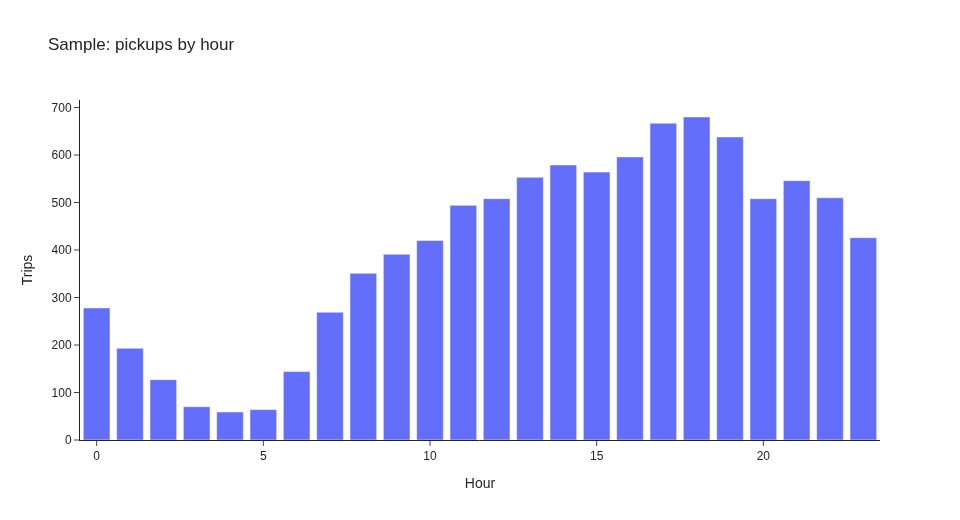

In [4]:
hourly = (
    population.groupby(population["pickup"].dt.hour)
    .size()
    .rename_axis("hour")
    .reset_index(name="trips")
)
fig = px.bar(
    hourly,
    x="hour",
    y="trips",
    title="Sample: pickups by hour",
    labels={"hour": "Hour", "trips": "Trips"},
)
fig.update_layout(template="simple_white")
show(fig)

The full year is already aggregated. This is the chart behind finding 1.

Peak hour 18: 2,821,218 trips (7.1%)


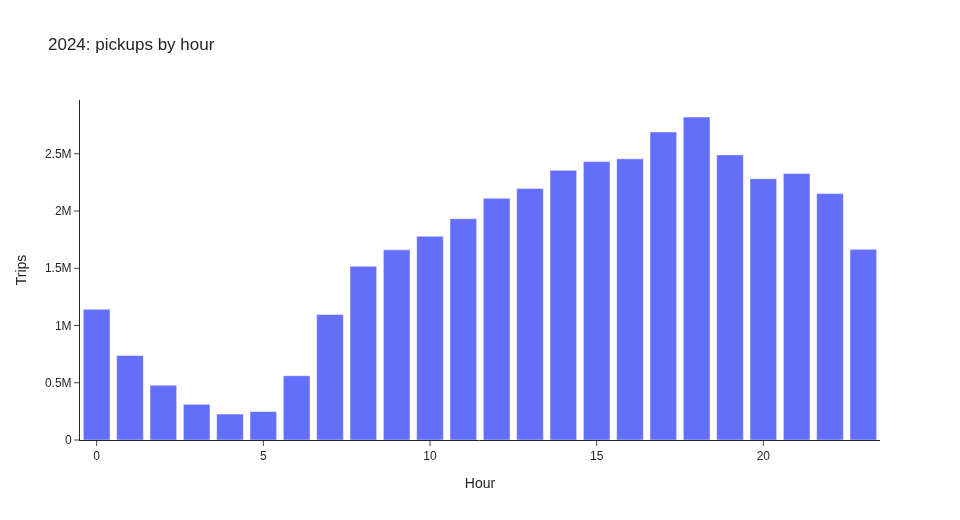

In [5]:
full_hourly = pd.read_csv(AGG / "02_hourly_demand.csv")
fig = px.bar(
    full_hourly,
    x="hour",
    y="trips",
    title="2024: pickups by hour",
    labels={"hour": "Hour", "trips": "Trips"},
)
fig.update_layout(template="simple_white")
peak = full_hourly.loc[full_hourly["trips"].idxmax()]
print(f"Peak hour {int(peak['hour'])}: {int(peak['trips']):,} trips ({peak['share']:.1%})")
show(fig)

## Where trips start

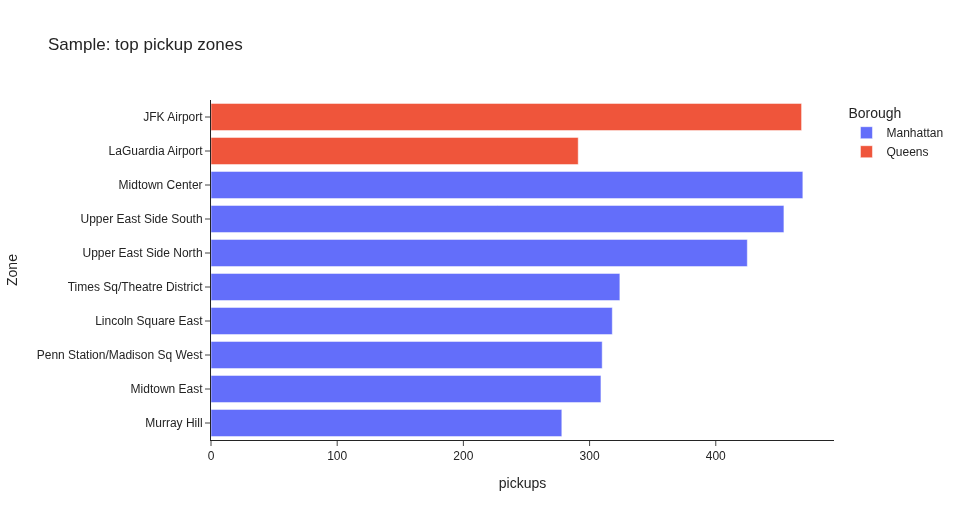

In [6]:
labeled = population.merge(
    zones,
    left_on="PULocationID",
    right_on="LocationID",
    how="left",
)
top_zones = (
    labeled.groupby(["Borough", "Zone"], as_index=False)
    .size()
    .rename(columns={"size": "pickups"})
    .sort_values("pickups", ascending=False)
    .head(10)
)
fig = px.bar(
    top_zones.sort_values("pickups"),
    x="pickups",
    y="Zone",
    color="Borough",
    orientation="h",
    title="Sample: top pickup zones",
)
fig.update_layout(template="simple_white")
show(fig)

Upper East Side South (Manhattan): 1,871,205 pickups


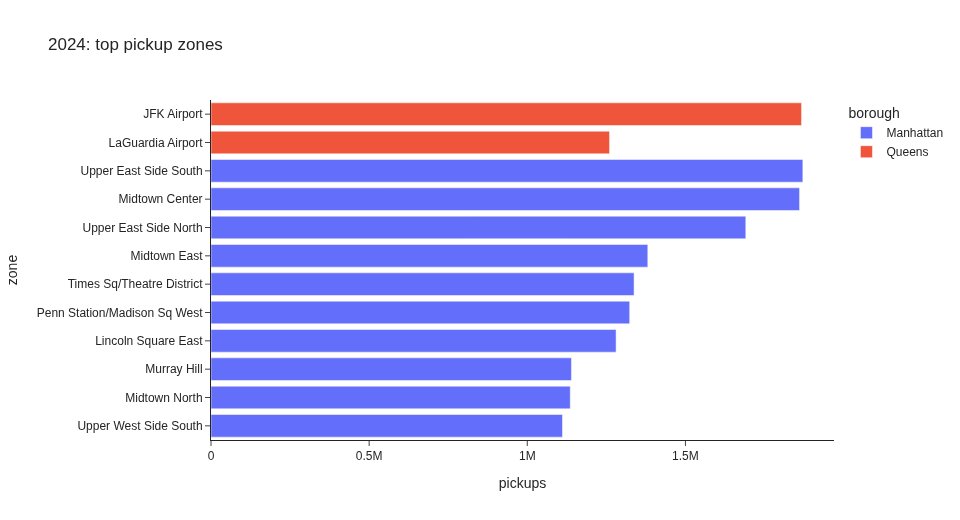

In [7]:
full_zones = pd.read_csv(AGG / "03_zone_rankings.csv")
top = full_zones.nsmallest(12, "city_rank").sort_values("pickups")
fig = px.bar(
    top,
    x="pickups",
    y="zone",
    color="borough",
    orientation="h",
    title="2024: top pickup zones",
)
fig.update_layout(template="simple_white")
leader = full_zones.loc[full_zones["city_rank"].idxmin()]
print(f"{leader['zone']} ({leader['borough']}): {int(leader['pickups']):,} pickups")
show(fig)

## Speed

Miles per hour from distance and duration. The full-year query drops speeds outside 0.5–80 mph before taking the median.

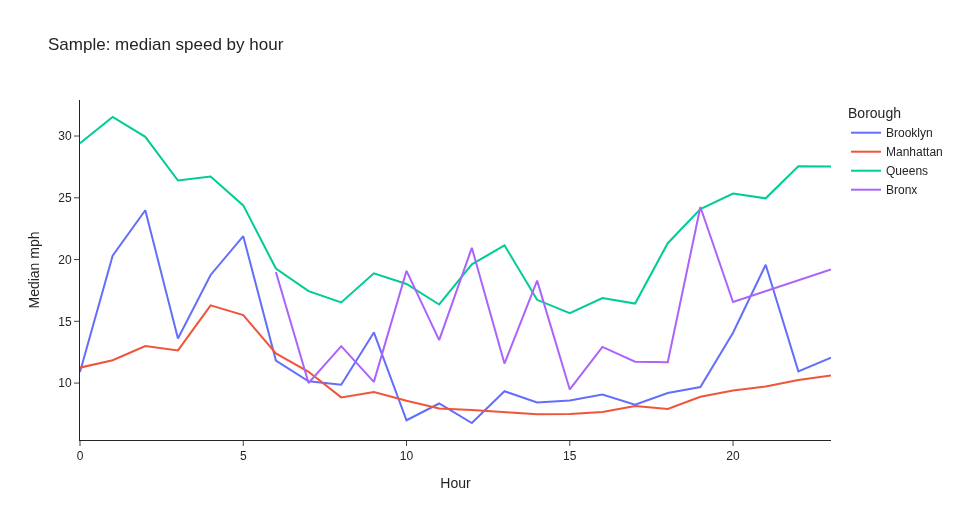

In [8]:
moving = population[population["duration_sec"].gt(0) & population["trip_distance"].gt(0)].copy()
moving["speed_mph"] = moving["trip_distance"] / (moving["duration_sec"] / 3600)
moving = moving[moving["speed_mph"].between(0.5, 80)].copy()
moving["hour"] = moving["pickup"].dt.hour
moving = moving.merge(
    zones[["LocationID", "Borough"]],
    left_on="PULocationID",
    right_on="LocationID",
    how="left",
)
speed = moving.groupby(["hour", "Borough"], as_index=False)["speed_mph"].median()
keep = ["Manhattan", "Brooklyn", "Queens", "Bronx"]
fig = px.line(
    speed[speed["Borough"].isin(keep)],
    x="hour",
    y="speed_mph",
    color="Borough",
    title="Sample: median speed by hour",
    labels={"speed_mph": "Median mph", "hour": "Hour"},
)
fig.update_layout(template="simple_white")
show(fig)

Slowest stable cell: Manhattan hour 15, 7.6 mph


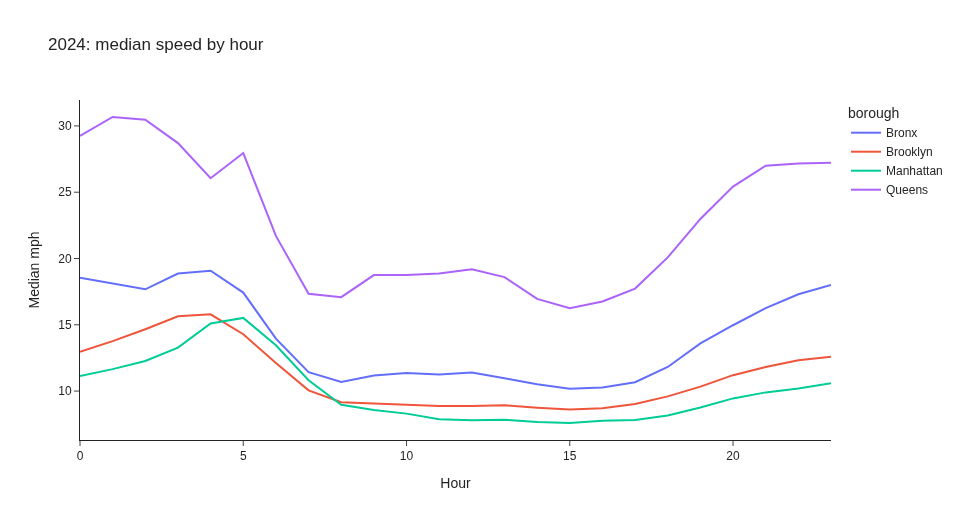

In [9]:
full_speed = pd.read_csv(AGG / "06_speed_by_hour_borough.csv")
boroughs = ["Manhattan", "Brooklyn", "Queens", "Bronx"]
fig = px.line(
    full_speed[full_speed["borough"].isin(boroughs)],
    x="hour",
    y="median_speed_mph",
    color="borough",
    title="2024: median speed by hour",
    labels={"median_speed_mph": "Median mph", "hour": "Hour"},
)
fig.update_layout(template="simple_white")
stable = full_speed[full_speed["trips"] >= 1000]
slow = stable.loc[stable["median_speed_mph"].idxmin()]
print(
    f"Slowest stable cell: {slow['borough']} hour {int(slow['hour'])}, "
    f"{slow['median_speed_mph']:.1f} mph"
)
show(fig)